# Predicting Batter Swing Probability Using Pitch Characteristics and Game Context

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

Baseball analytics has become an important tool for teams that looking for a competitive edge, particularly in understanding the interaction between pitchers and batters. One key aspect of this interaction is whether a batter chooses to swing at a given pitch, which can influence the outcome of an at-bat. Unlike many traditional classification problems, this task is more about accurate probability estimation rather than simple prediciton, as team rely on well-calibrated probabilities to inform strategic decisions, and poorly calibrated models can lead to misleading conclusions about pitch effectiveness. This report investigates whether machine learning models can effectively estimate the probability that a batter swings at a pitch using pitch characteristics and game context data. The dataset consists of pitch-level observations from Zac Gallen during teh 2023 MLB season, including features such as pitch type, velocity, location, movement, and situational variables like count and base runners. The goal is to develop a well-calibrated model that produces reliable probability estimates, enabling better decision-making for pitch strategies in real-world scenarios. 

## Methods

In [1]:
# imports
import pandas as pd
import numpy as np
from joblib import dump
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier

### Data

In [2]:
# load data
swing_train = pd.read_csv(
    "swing-train.csv",
)
swing_test = pd.read_csv(
    "swing-test.csv",
)

The dataset contains pitch-level information from Zac Gallen during the 2023 MLB regular season. Each observation represents a single pitch and includes the following variables:

| Category | Variable | Type | Description |
|----------|----------|------|-------------|
| Response | swing | int64 | Whether or not the batter swung (1) or took (0). |
| Fully Pitcher Controlled | pitch_name | object | The name of the pitch type to be thrown. |
| Mostly Pitcher Controlled | release_extension | float64 | Release extension of pitch in feet as tracked by Statcast. |
| Mostly Pitcher Controlled | release_pos_x | float64 | Horizontal release position of the ball measured in feet from the catcher’s perspective. |
| Mostly Pitcher Controlled | release_pos_y | float64 | Release position of pitch measured in feet from the catcher’s perspective. |
| Mostly Pitcher Controlled | release_pos_z | float64 | Vertical release position of the ball measured in feet from the catcher’s perspective. |
| Somewhat Pitcher Controlled | release_speed | float64 | Velocity of the pitch thrown (miles per hour). |
| Somewhat Pitcher Controlled | release_spin_rate | float64 | Spin rate of pitch tracked by Statcast (revolutions per minute). |
| Somewhat Pitcher Controlled | spin_axis | float64 | The spin axis in the 2D X-Z plane in degrees from 0 to 360, such that 180 represents a pure backspin fastball and 0 degrees represents a pure topspin (12-6) curveball. |
| Somewhat Pitcher Controlled | plate_x | float64 | Horizontal position of the ball when it crosses home plate from the catcher’s perspective (feet). |
| Somewhat Pitcher Controlled | plate_z | float64 | Vertical position of the ball when it crosses home plate from the catcher’s perspective (feet). |
| Downstream Pitcher Controlled | pfx_x | float64 | Horizontal movement in feet from the catcher’s perspective. |
| Downstream Pitcher Controlled | pfx_z | float64 | Vertical movement in feet from the catcher’s perspective. |
| Situational Information | balls | int64 | Pre-pitch number of balls in count. |
| Situational Information | strikes | int64 | Pre-pitch number of strikes in count. |
| Situational Information | on_3b | int64 | Indicator (0 or 1) for runner on 3rd base. |
| Situational Information | on_2b | int64 | Indicator (0 or 1) for runner on 2nd base. |
| Situational Information | on_1b | int64 | Indicator (0 or 1) for runner on 1st base. |
| Situational Information | outs_when_up | int64 | Pre-pitch number of outs. |
| Fixed Batter Information | stand | object | Side of the plate batter is standing, either L (left) or R (right). |
| Fixed Batter Information | sz_top | float64 | Top of the batter’s strike zone set by the operator when the ball is halfway to the plate (feet). |
| Fixed Batter Information | sz_bot | float64 | Bottom of the batter’s strike zone set by the operator when the ball is halfway to the plate (feet). |

Shape of the dataset:

In [3]:
# summary statistics
swing_train.shape

(2663, 22)

The proportion of whether or not the batter swung or took:

In [4]:
swing_train["swing"].value_counts(normalize=True)

swing
0    0.522719
1    0.477281
Name: proportion, dtype: float64

The proportion of each pitch is swung at or not:

In [5]:
swing_train.groupby("pitch_name")["swing"].value_counts(normalize=True)

pitch_name       swing
4-Seam Fastball  0        0.529096
                 1        0.470904
Changeup         1        0.536313
                 0        0.463687
Cutter           0        0.548523
                 1        0.451477
Knuckle Curve    0        0.537125
                 1        0.462875
Slider           0        0.503876
                 1        0.496124
Name: proportion, dtype: float64

My summary statistics show that the dataset contains 2,663 pitches and 21 features. I computed the proportion of pitches where the batter swung or did not swing, finding that swings occur in approximately 47.7% of pitches, while batters take pitches about 52.3% of the time, indicating a fairly balanced response variable. I also examined how swing behavior varies by pitch type, observing that certain pitches, such as changeups, are more likely to induce swings compared to others like cutters and knuckle curves. These differences suggest that pitch type plays an important role in influencing batter decisions and will likely be an important feature for modeling swing probability.

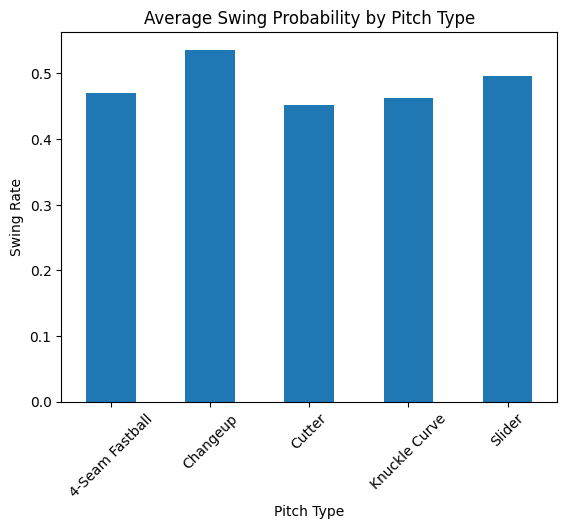

In [6]:
#| fig-cap: "Figure 1. Swing Rate by Pitch Type in the Training Data"
# exploratory visualization
swing_rate = swing_train.groupby("pitch_name")["swing"].mean()

swing_rate.plot(kind="bar")

plt.xlabel("Pitch Type")
plt.ylabel("Swing Rate")
plt.title("Average Swing Probability by Pitch Type")

plt.xticks(rotation=45)

plt.show()

### Models

In [7]:
# process data for ML
# create X and y for train
X_train = swing_train.drop("swing", axis=1)
y_train = swing_train["swing"]

# create X and y for test
X_test = swing_test.drop("swing", axis=1)
y_test = swing_test["swing"]

In [8]:
# train models
X_train = swing_train.drop("swing", axis=1).fillna(0)
y_train = swing_train["swing"]

cat_cols = ["pitch_name", "stand"]

preprocessor = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
    remainder="passthrough"
)

base_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingClassifier(max_iter=200, max_depth=5, random_state=42))
])

model = CalibratedClassifierCV(base_model, method="sigmoid", cv=5)

model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...m_state=42))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...002A168B13770>, <sk

The swing prediction task was treated as a binary classification problem, where the goal is to predict whether a batter swings at a pitch or not. A Histogram-Based Gradient Boosting classifier was used due to its strong performance on structured data and its ability to capture nonlinear relationships between pitch characteristics and batter behavior. The model was trained with 200 boosting iterations and a maximum tree depth of 5, allowing it to learn complex patterns while maintaining generalization. Since the dataset contains both categorical and numerical features, a preprocessing pipeline was implemented using a ColumnTransformer, where categorical variables such as pitch type and batter stance were encoded using one-hot encoding, and numerical features were passed through unchanged. To ensure that the predicted probabilities are reliable, the model was further calibrated using CalibratedClassifierCV with sigmoid calibration and 5-fold cross-validation. The model was trained on the full training dataset and then used to generate predictions on unseen test data to evaluate its performance.

## Results

In [9]:
def calibration_error(y_true, y_prob, type="expected", n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.searchsorted(bins[1:-1], y_prob)

    bin_sums = np.bincount(binids, weights=y_prob, minlength=len(bins))
    bin_true = np.bincount(binids, weights=y_true, minlength=len(bins))
    bin_total = np.bincount(binids, minlength=len(bins))

    nonzero = bin_total != 0
    prob_true = bin_true[nonzero] / bin_total[nonzero]
    prob_pred = bin_sums[nonzero] / bin_total[nonzero]

    if type == "max":
        calibration_error = np.max(np.abs(prob_pred - prob_true))
    elif type == "expected":
        bin_error = np.abs(prob_pred - prob_true) * bin_total[nonzero]
        calibration_error = np.sum(bin_error) / len(y_true)

    return calibration_error


In [10]:
# report model metrics
y_prob = model.predict_proba(X_test)[:, 1]

ece = calibration_error(y_test, y_prob, type="expected")
mce = calibration_error(y_test, y_prob, type="max")
brier = brier_score_loss(y_test, y_prob)

print("Test ECE:", ece)
print("Test MCE:", mce)
print("Test Brier Score:", brier)

Test ECE: 0.049543578316742845
Test MCE: 0.10550399929390131
Test Brier Score: 0.17850285813298739


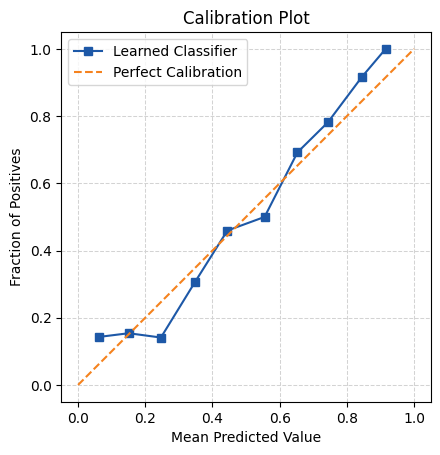

In [11]:
#| fig-cap: "Figure 2. Calibration Plot for Swing Probability Model on the Test Dataset"
# summary figure
# function to plot a calibration_plot
def plot_calibration_plot(y_true, y_prob):

    # generate "data" for calibration plot
    prob_true, prob_pred = calibration_curve(
        y_true,
        y_prob,
        n_bins=10,
        pos_label=1,
    )

    # create a figure and axis object with a specific size
    fig, ax = plt.subplots()

    # plot the calibration curve
    ax.plot(
        prob_pred,
        prob_true,
        "s-",
        label="Learned Classifier",
        color="#1D58A7",
    )

    # plot the diagonal "perfect" line
    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        label="Perfect Calibration",
        color="#F5821E",
    )

    # set the plot title and axis labels
    ax.set_title("Calibration Plot")
    ax.set_xlabel("Mean Predicted Value")
    ax.set_ylabel("Fraction of Positives")

    # add a grid
    ax.grid(
        True,
        color="lightgrey",
        linewidth=0.75,
        linestyle="--",
    )

    # fix aspect ratio
    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    # show the legend
    ax.legend()

    # show the plot
    plt.show()

plot_calibration_plot(y_test, y_prob)

Overall, the results indicate that the model provides strong performance in estimating swing probabilities. The model achieved a low Brier Score of approximately 0.178, indicating that the predicted probabilities are close to the true outcomes. Additionally, the Expected Calibration Error (ECE) of about 0.049 and Maximum Calibration Error (MCE) of about 0.105 both fall well below the required thresholds, demonstrating that the model’s probability estimates are well-calibrated. The calibration plot further supports this, as the predicted probabilities closely follow the ideal diagonal line, with only minor deviations at lower probability ranges. Together, these results suggest that the model produces reliable and accurate probability estimates, making it effective for predicting batter swing behavior.

## Discussion

Based on the results presented above, I would recommend using this model in practice as part of a decision-support system for pitching strategy. The model demonstrates strong performance in estimating swing probabilities, achieving low Brier Score, Expected Calibration Error (ECE), and Maximum Calibration Error (MCE), all of which indicate that the predicted probabilities are both accurate and well-calibrated. This is especially important in this application, as the goal is not simply to classify whether a batter will swing, but to provide reliable probability estimates that coaches and analysts can use to make informed decisions about pitch selection.

One important benefit of this model is that it can consistently evaluate how different pitch characteristics and game situations influence swing behavior. This allows analysts to identify which pitch types and locations are more likely to induce swings, providing actionable insights for pitchers like Zac Gallen. Because the model is well-calibrated, a predicted probability (e.g., 0.7) can be interpreted meaningfully as a 70% chance of a swing, which is critical when making strategic decisions. In practice, the model could be used to guide pitch selection, helping pitchers choose pitches that maximize the likelihood of inducing weak contact or swings in unfavorable situations for the batter.

However, several limitations should also be considered. While the model performs well overall, it is not perfectly calibrated across all probability ranges, and small deviations in the calibration plot suggest that predictions may be less reliable in certain regions. Errors in probability estimation can have real consequences; for example, overestimating swing probability could lead a pitcher to throw a pitch designed to induce a swing when the batter is more likely to take, potentially resulting in a ball or walk. Conversely, underestimating swing probability might cause missed opportunities to exploit aggressive hitters. Additionally, the model is trained on data from a single pitcher, which limits its generalizability to other pitchers or teams. It also does not incorporate more detailed batter-specific tendencies or contextual factors such as game pressure, which may influence swing decisions.

For these reasons, the model should not be used as a fully automated decision-maker without oversight. Instead, it would be most effective as part of a broader analytics system, where its probability estimates are used alongside expert judgment and additional scouting information. This approach allows the model to enhance decision-making while reducing the risk of relying on imperfect predictions.

Overall, the model demonstrates that machine learning can effectively estimate swing probabilities using pitch-level data. While it is not without limitations, it provides reliable and interpretable probability estimates that can support pitching strategy, improve decision-making, and offer a meaningful competitive advantage when used appropriately in a real-world baseball analytics setting.